# Demo 1 — Learning a proportion: exact, grid and Stan

**Day 2 · Bayesian statistics · Aalborg University 2026** · shown in Lecture A (morning)

Run it from top to bottom after the course, then change the numbers in the *Try this* list at the end.

**The question (invented data).** A city bus line got a new timetable. We watched the first **20** departures and **14** left on time. What can we say about **θ, the probability that a departure is on time**?

We answer it in three ways and check that they agree:

1. **exact**, with the beta–binomial update rule;
2. **grid**, by multiplying prior and likelihood on many θ values;
3. **Stan**, which gives us random draws from the posterior.

**R used in this notebook.** `tibble()` makes a small table; `|>` reads as "and then"; `mutate()` adds a column; `bind_rows()` stacks tables on top of each other; `count(k)` counts how often each value of `k` occurs. Everything else is base R: `dbeta`, `qbeta`, `pbeta`, `rbeta` (and the same for `binom`, `pois`, `gamma`).

In [1]:
options(tidyverse.quiet = TRUE)
library(tidyverse)   # tibble, dplyr and ggplot2
suppressPackageStartupMessages(library(cmdstanr))   # runs Stan from R
set.seed(2026)
theme_set(theme_minimal(base_size = 13))

## 1. Data and prior

*Slides: "The beta distribution: a prior for a proportion".*

- Data: n = 20 departures, y = 14 on time.
- Prior: **Beta(2, 2)**. Its mean is a / (a + b) = 0.5 and it gently down-weights values near 0 and 1. You can read a and b as "about 2 earlier on-time departures and 2 late ones".

In [2]:
n <- 20    # departures watched
y <- 14    # departures on time
a <- 2     # prior Beta(a, b)
b <- 2

## 2. The exact posterior

*Slides: "The beta–binomial update".*

A Beta(a, b) prior and y successes in n trials give the posterior

$$\theta \mid y \sim \text{Beta}(a + y,\; b + n - y)$$

so we add the successes to a and the failures to b.

In [3]:
a_post <- a + y          # 2 + 14 = 16
b_post <- b + n - y      # 2 + 6  = 8
c(a_post = a_post, b_post = b_post)

a_post b_post 
    16      8

*Slides: "Summarising the posterior Beta(16, 8)".* The mean is a / (a + b); `qbeta()` gives quantiles (for the interval); `pbeta(0.6, …)` gives P(θ ≤ 0.6), so 1 minus it gives P(θ > 0.6).

In [4]:
exact <- c(
  mean      = a_post / (a_post + b_post),
  lower_90  = qbeta(0.05, a_post, b_post),
  upper_90  = qbeta(0.95, a_post, b_post),
  p_above_6 = 1 - pbeta(0.6, a_post, b_post)    # P(theta > 0.6 | data)
)
round(exact, 3)

mean  lower_90  upper_90 p_above_6 
    0.667     0.504     0.814     0.763

## 3. Prior, likelihood and posterior in one plot

*Slides: "The likelihood: binomial in y, a curve in θ" and "Prior × likelihood → posterior".*

We compute each curve on a grid of θ values from 0 to 1 and draw all three.

The likelihood `dbinom(14, 20, θ)` is a function of θ, not a distribution for θ, so the area under it is not 1. To draw it on the same scale as the two densities we divide it by its area. The area is approximated by thin bars: height × width, added up.

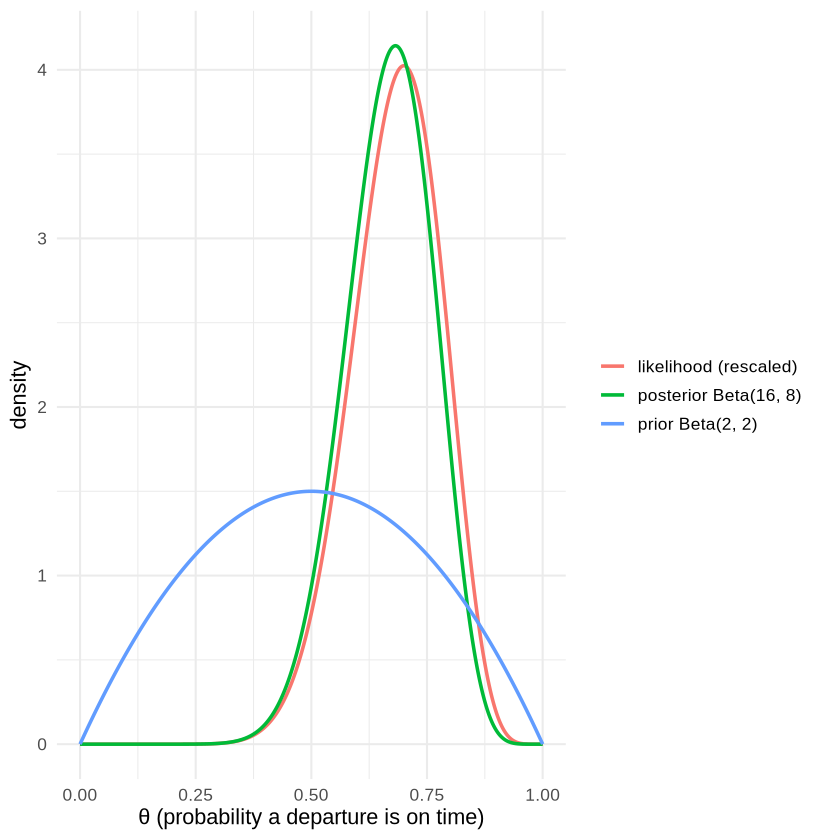

In [5]:
theta <- seq(0, 1, length.out = 501)   # grid of θ values
delta <- theta[2] - theta[1]            # width of one grid step: 0.002

prior      <- dbeta(theta, a, b)
likelihood <- dbinom(y, n, theta)
likelihood <- likelihood / sum(likelihood * delta)   # divide by the area: sum of height x width
posterior  <- dbeta(theta, a_post, b_post)

curves <- bind_rows(
  tibble(theta = theta, density = prior,      curve = "prior Beta(2, 2)"),
  tibble(theta = theta, density = likelihood, curve = "likelihood (rescaled)"),
  tibble(theta = theta, density = posterior,  curve = "posterior Beta(16, 8)")
)

ggplot(curves, aes(x = theta, y = density, colour = curve)) +
  geom_line(linewidth = 1) +
  labs(x = "θ (probability a departure is on time)", y = "density", colour = NULL)

**What to see:** the posterior lies between the prior (centred at 0.5) and the likelihood (peak at 14/20 = 0.7), much closer to the likelihood.

## 4. The posterior mean is a compromise

*Slides: "The posterior mean is a compromise".*

$$E[\theta\mid y] = \frac{a+y}{a+b+n} = w\cdot\frac{a}{a+b} + (1-w)\cdot\frac{y}{n},\qquad w = \frac{a+b}{a+b+n}$$

The prior acts like a + b = 4 extra departures, so it gets the weight w = 4 / 24.

In [6]:
w <- (a + b) / (a + b + n)       # weight on the prior: 4 / 24
c(prior_mean     = a / (a + b),
  data_mean      = y / n,
  weight_prior   = w,
  compromise     = w * a / (a + b) + (1 - w) * y / n,
  posterior_mean = a_post / (a_post + b_post))     # the same number as "compromise"

prior_mean      data_mean   weight_prior     compromise posterior_mean 
     0.5000000      0.7000000      0.1666667      0.6666667      0.6666667

## 5. Updating one departure at a time

*Slides: "Updating one departure at a time"* (the same idea as the marble game on Day 1).

After each departure, today's posterior becomes the prior for the next departure. `cumsum()` is a running total: after k departures, a has grown by the number on time so far and b by the number late so far.

In [7]:
outcomes <- sample(c(rep(1, y), rep(0, n - y)))   # one possible order: 1 = on time, 0 = late, random permutation

sequential <- tibble(k = 1:n, on_time = outcomes) |>
  mutate(
    a_k   = a + cumsum(on_time),          # a + on-time departures so far
    b_k   = b + cumsum(1 - on_time),      # b + late departures so far
    mean  = a_k / (a_k + b_k),
    lower = qbeta(0.05, a_k, b_k),
    upper = qbeta(0.95, a_k, b_k)
  )

tail(sequential, 1)    # after all 20: Beta(16, 8), the same as updating all at once

k,on_time,a_k,b_k,mean,lower,upper
<int>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
20,0,16,8,0.6666667,0.5035649,0.8136562


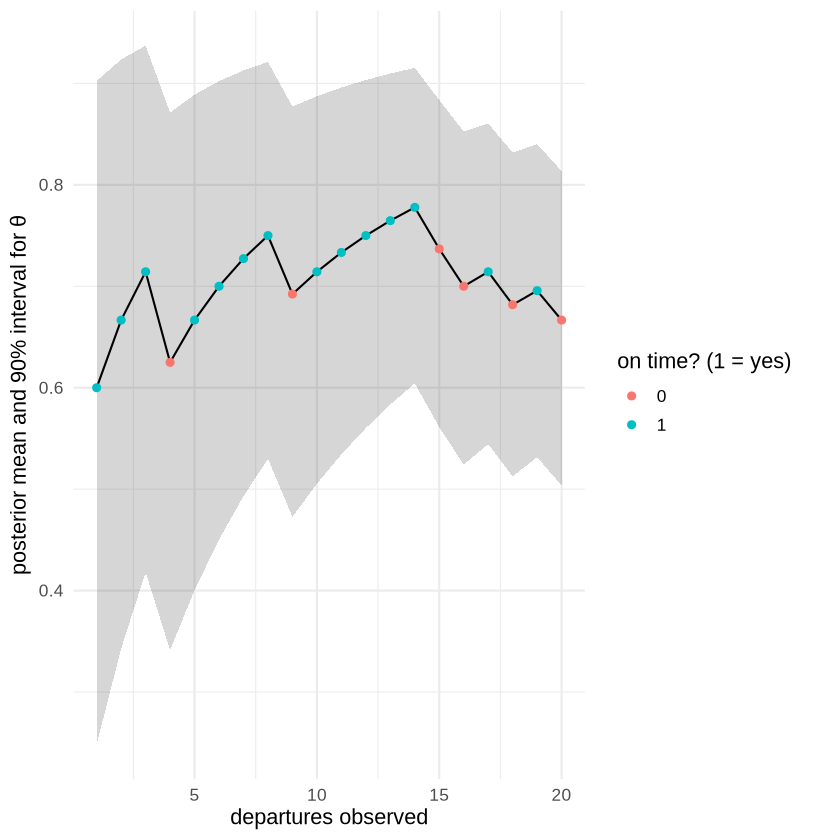

In [8]:
ggplot(sequential, aes(x = k, y = mean)) +
  geom_ribbon(aes(ymin = lower, ymax = upper), alpha = 0.2) +
  geom_line() +
  geom_point(aes(colour = factor(on_time))) +
  labs(x = "departures observed", y = "posterior mean and 90% interval for θ",
       colour = "on time? (1 = yes)")

## 6. How much does the prior matter?

*Slides: "How much does the prior matter?".*

Three people see the same 14 of 20 but start from different priors. Each gets its own Beta posterior by the same update rule.

In [9]:
priors <- tibble(
  prior = c("flat Beta(1, 1)", "mild Beta(2, 2)", "operator says 80%: Beta(20, 5)"),
  a     = c(1, 2, 20),
  b     = c(1, 2, 5)
)

priors |>
  mutate(a_post    = a + y,
         b_post    = b + n - y,
         mean      = a_post / (a_post + b_post),
         lower_90  = qbeta(0.05, a_post, b_post),
         upper_90  = qbeta(0.95, a_post, b_post),
         p_above_6 = 1 - pbeta(0.6, a_post, b_post))

prior,a,b,a_post,b_post,mean,lower_90,upper_90,p_above_6
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
"flat Beta(1, 1)",1,1,15,7,0.6818182,0.5126112,0.8318242,0.7997540
"mild Beta(2, 2)",2,2,16,8,0.6666667,0.5035649,0.8136562,0.7627291
"operator says 80%: Beta(20, 5)",20,5,34,11,0.7555556,0.6450512,0.8530181,0.9876267


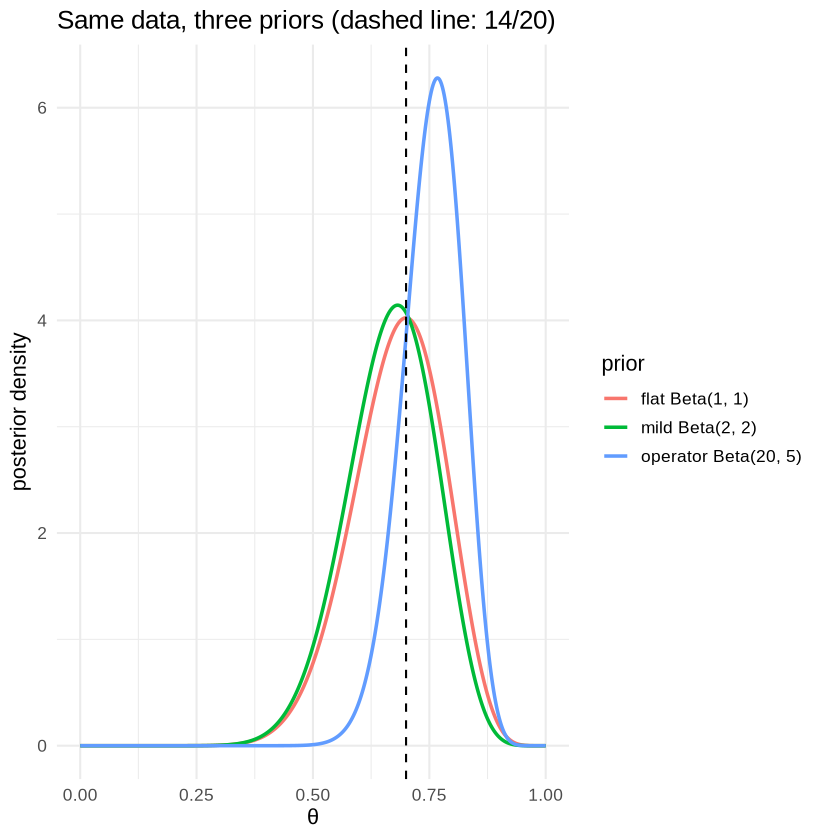

In [10]:
posteriors <- bind_rows(
  tibble(theta = theta, density = dbeta(theta, 1 + y, 1 + n - y),  prior = "flat Beta(1, 1)"),
  tibble(theta = theta, density = dbeta(theta, 2 + y, 2 + n - y),  prior = "mild Beta(2, 2)"),
  tibble(theta = theta, density = dbeta(theta, 20 + y, 5 + n - y), prior = "operator Beta(20, 5)")
)

ggplot(posteriors, aes(x = theta, y = density, colour = prior)) +
  geom_line(linewidth = 1) +
  geom_vline(xintercept = y / n, linetype = "dashed") +
  labs(x = "θ", y = "posterior density", colour = "prior", title = "Same data, three priors (dashed line: 14/20)")

**What to see:** the flat and the mild prior give almost the same posterior. The operator's prior counts as 20 + 5 = 25 departures, more than the 20 we watched, so it pulls the posterior towards 0.8.

## 7. When there is no formula: a grid

*Slides: "When there is no formula: a grid".* This is also Exercise A3.

1. Take many θ values between 0 and 1.
2. At each one, compute prior × likelihood.
3. Divide by the sum, so the weights add up to 1.
4. Use the weights like probabilities: mean = sum(θ × weight); P(θ > 0.6) = sum of the weights where θ > 0.6.

This works for **any** prior, also one without a name.

In [11]:
grid_theta <- seq(0, 1, length.out = 1001)
weight     <- dbeta(grid_theta, a, b) * dbinom(y, n, grid_theta)   # prior x likelihood
weight     <- weight / sum(weight)                                  # weights add up to 1

c(grid_mean   = sum(grid_theta * weight),
  exact_mean  = a_post / (a_post + b_post),
  grid_prob   = sum(weight[grid_theta > 0.6]),
  exact_prob  = 1 - pbeta(0.6, a_post, b_post))

grid_mean exact_mean  grid_prob exact_prob 
 0.6666667  0.6666667  0.7612163  0.7627291

## 8. The same model in Stan

*Slides: "First look at Stan", "The bus model in Stan", "Running it from R".*

Stan does not know the update rule. We only tell it the **prior** and the **likelihood**; it returns thousands of random **draws** of θ from the posterior. Here we can check Stan against the exact answer; later in the week we fit models that have no formula.

The program has three blocks: `data` (what we know), `parameters` (what we want to learn) and `model` (prior and likelihood). The `generated quantities` block is used in section 9.

In [12]:
writeLines(readLines("models/beta_binomial.stan"))

// Day 2 demo: the beta-binomial model in Stan
// y successes out of n trials, unknown success probability theta.

data {
  int<lower=0> n;                 // number of trials
  int<lower=0, upper=n> y;        // number of successes
  real<lower=0> a;                // prior: Beta(a, b)
  real<lower=0> b;
}

parameters {
  real<lower=0, upper=1> theta;   // success probability
}

model {
  theta ~ beta(a, b);             // prior
  y ~ binomial(n, theta);         // likelihood
}

generated quantities {
  // a prediction: successes in the next 10 trials
  int y_next10 = binomial_rng(10, theta);
}


Compile the program once (about a minute the first time), then sample. The data go in as a named list, with the same names as in the `data` block.

In [13]:
mod <- cmdstan_model("models/beta_binomial.stan")

fit <- mod$sample(
  data = list(n = n, y = y, a = a, b = b),
  chains = 4, iter_sampling = 2000, seed = 2026, refresh = 0
)

Running MCMC with 4 sequential chains...

Chain 1 finished in 0.0 seconds.
Chain 2 finished in 0.0 seconds.
Chain 3 finished in 0.0 seconds.
Chain 4 finished in 0.0 seconds.

All 4 chains finished successfully.
Mean chain execution time: 0.0 seconds.
Total execution time: 0.6 seconds.



`fit$draws(format = "draws_df")` gives a table with one row per draw (4 chains × 2000 = 8000 draws). A posterior probability from draws is the **share of draws** for which the statement is true, for example `mean(theta > 0.6)`.

In [14]:
draws <- fit$draws(format = "draws_df")

stan <- c(
  mean      = mean(draws$theta),
  lower_90  = unname(quantile(draws$theta, 0.05)),   # unname() drops the label "5%"
  upper_90  = unname(quantile(draws$theta, 0.95)),
  p_above_6 = mean(draws$theta > 0.6)                # share of draws above 0.6
)

round(rbind(exact = exact, stan = stan), 3)

,mean,lower_90,upper_90,p_above_6
exact,0.667,0.504,0.814,0.763
stan,0.669,0.504,0.818,0.768


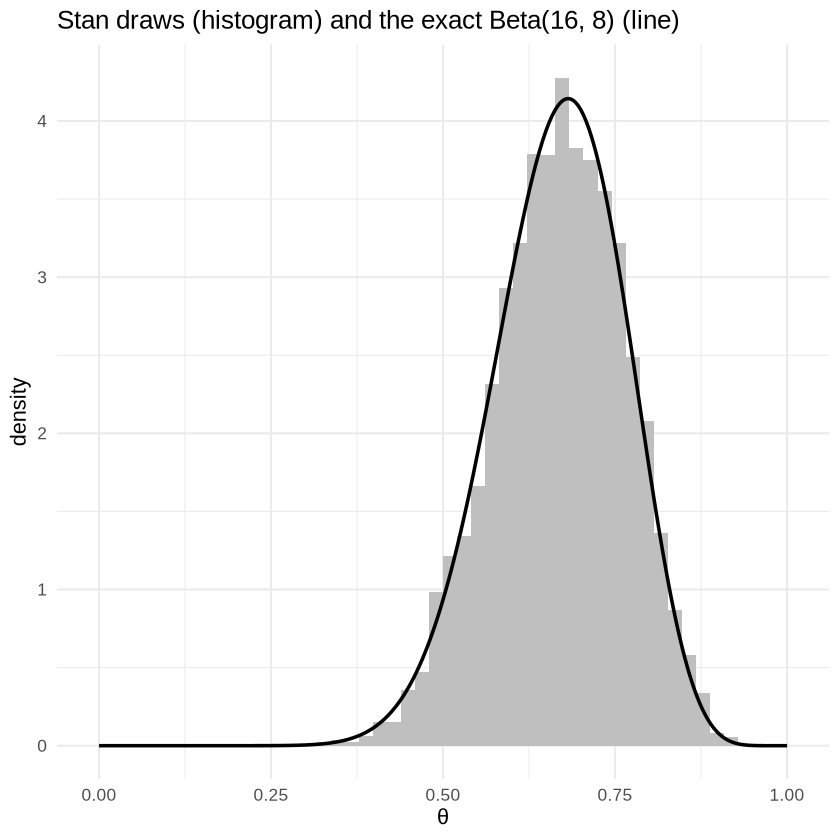

In [15]:
exact_curve <- tibble(theta = theta, density = dbeta(theta, a_post, b_post))

ggplot(draws, aes(x = theta)) +
  geom_histogram(aes(y = after_stat(density)), bins = 50, fill = "grey75") +   # Stan draws
  geom_line(data = exact_curve, aes(x = theta, y = density), linewidth = 1) +  # exact Beta(16, 8)
  labs(x = "θ", y = "density", title = "Stan draws (histogram) and the exact Beta(16, 8) (line)")

Stan's numbers differ slightly from the exact ones because they come from a finite number of random draws. Day 3 explains how to check that a Stan fit can be trusted; the columns `rhat` (close to 1) and `ess_bulk` (large) below already look fine.

In [16]:
fit$summary("theta")

variable,mean,median,sd,mad,q5,q95,rhat,ess_bulk,ess_tail
<chr>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>,<dbl>
theta,0.668969,0.6725028,0.09515278,0.09848589,0.5036219,0.8176504,1.001233,2680.163,3838.114


## 9. Prediction: how many of the next 10 departures will be on time?

*Slides (afternoon): "Posterior prediction: two kinds of uncertainty" and "Predicting the next 10 departures".*

A prediction is simulated in **two steps**: first draw θ from the posterior, then draw new data given that θ.

- In Stan, the `generated quantities` block did this once per draw and stored it as `y_next10`.
- In R we can do the same two steps with `rbeta()` and `rbinom()`.

Both should give the same distribution.

In [17]:
theta_draw <- rbeta(8000, a_post, b_post)        # step 1: θ from the posterior
y_sim      <- rbinom(8000, 10, theta_draw)        # step 2: next 10 departures given θ

c(stan_P_at_least_8 = mean(draws$y_next10 >= 8),
  R_P_at_least_8    = mean(y_sim >= 8))

stan_P_at_least_8    R_P_at_least_8 
          0.34925           0.33800

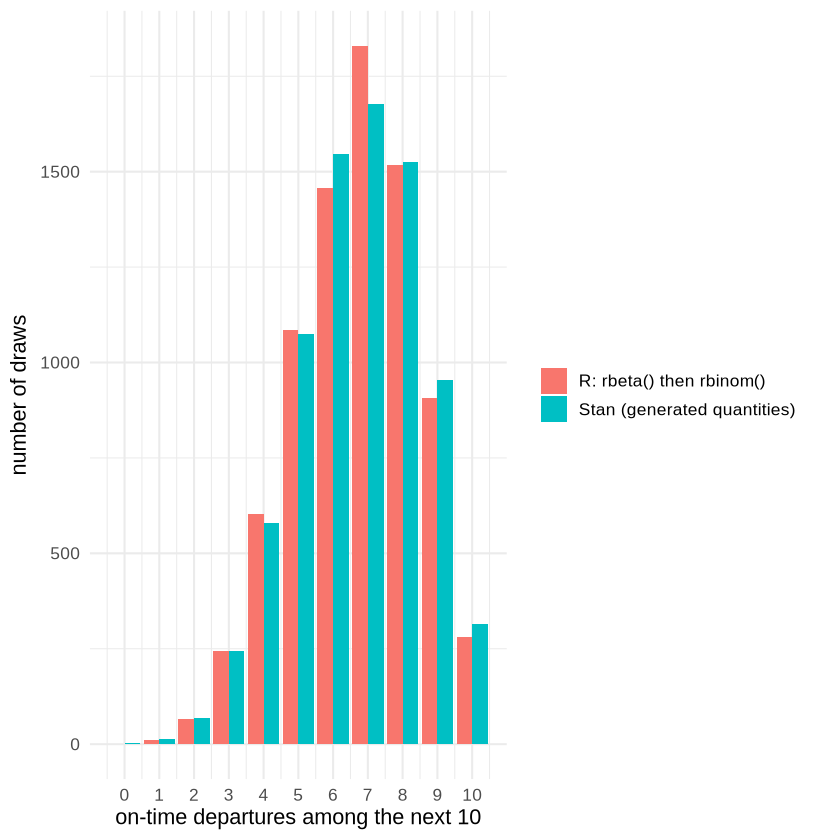

In [18]:
predictions <- bind_rows(
  tibble(on_time = draws$y_next10, method = "Stan (generated quantities)"),
  tibble(on_time = y_sim,          method = "R: rbeta() then rbinom()")
)

ggplot(predictions, aes(x = on_time, fill = method)) +
  geom_bar(position = "dodge") +
  scale_x_continuous(breaks = 0:10) +
  labs(x = "on-time departures among the next 10", y = "number of draws", fill = NULL)

## Try this

- Change the prior to Beta(20, 5) in section 1 and rerun. Predict first: does the posterior mean go up or down, and by about how much?
- Keep the proportion 0.7 but use n = 200, y = 140. What happens to the interval, and to the effect of the prior?
- Change `iter_sampling` to 200 in section 8. How close are Stan's numbers to the exact ones now?